In [2]:
import lightkurve as lk
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
import ipywidgets as wd

In [3]:
#Getting all the data
search = lk.search_lightcurve("KIC 12557548", mission="Kepler", author="Kepler",
                              exptime="long", quarter=[2, 3, 4, 5, 6])
sap_flux_col = search.download_all(flux_column="sap_flux")

period = 0.65356 

In [4]:
#Manipulating the data

stitched_data = sap_flux_col.stitch().remove_nans() #stitching the quarters together
clipped_data = stitched_data.remove_outliers(   #clipping the upper spikes, didn't really work
    sigma_upper=3,
    sigma_lower=float("inf")
)
time = clipped_data.time.mjd - 55000  #adjusting time same as in paper
flattened_data = clipped_data.flatten(window_length=31).flux.value  #convolving data to keep important signals

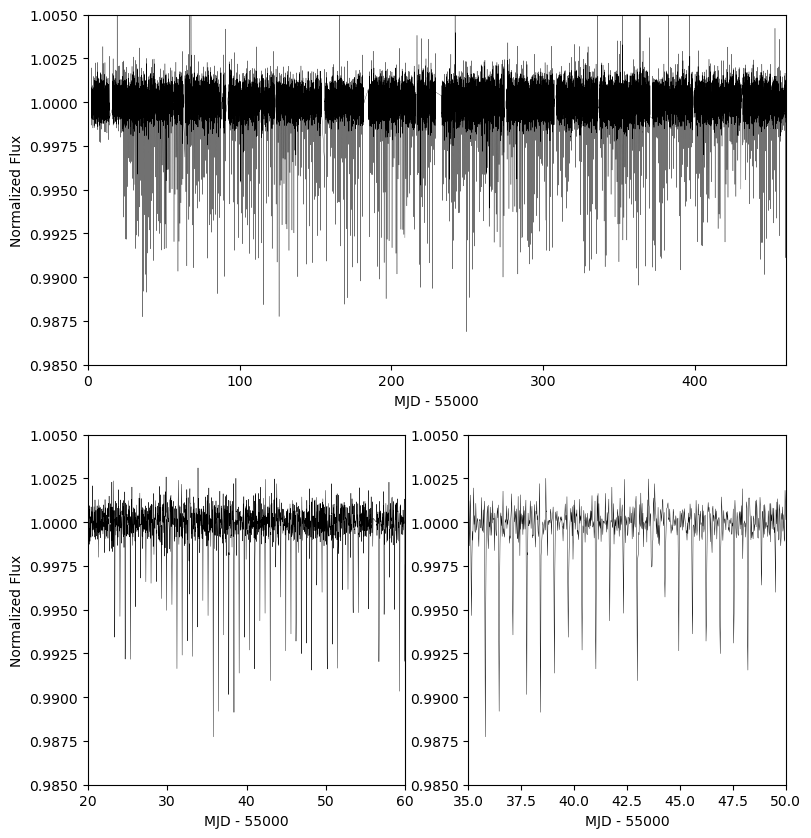

In [5]:
#Plotting Figure 1
plt.figure(figsize=(9, 10))


plt.subplot(2, 1, 1)
plt.plot(time, flattened_data, color = "black", linestyle = "-", linewidth=0.2)
plt.xlim(0, 460)
plt.ylim(0.985, 1.005)
plt.xlabel("MJD - 55000")
plt.ylabel("Normalized Flux")



plt.subplot(2, 2, 3)
plt.plot(time, flattened_data, color = "black", linestyle = "-", linewidth=0.3)
plt.xlim(20, 60)
plt.ylim(0.985, 1.005)
plt.xlabel("MJD - 55000")
plt.ylabel("Normalized Flux")



plt.subplot(2, 2, 4)
plt.plot(time, flattened_data, color = "black", linestyle = "-", linewidth=0.3)
plt.xlim(35, 50)
plt.ylim(0.985, 1.005)
plt.xlabel("MJD - 55000")


plt.show()

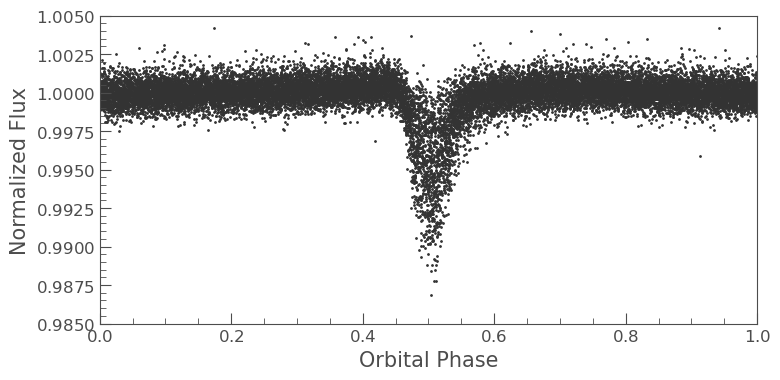

In [6]:
#Plotting Figure 2 a
clipped_data_detrended = lk.LightCurve(time=clipped_data.time, flux=flattened_data) #why was this detrended?

folded_data = clipped_data_detrended.fold(period=0.65356, epoch_time=567.324*u.day, normalize_phase=True, epoch_phase=0.5, wrap_phase=1)  #why this epoch time? what about the equation?

folded_data.scatter()
plt.xlim(0,1)
plt.ylim(0.985,1.005)
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")

plt.show()

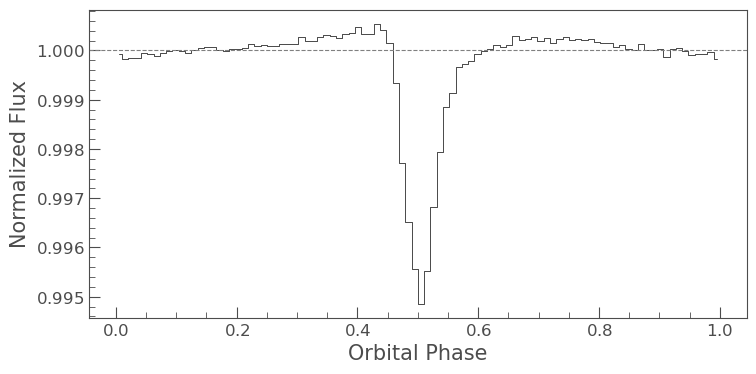

In [7]:
#Plotting Figure 2 b
binned_data = folded_data.bin(bins=96)
binned_data.plot(color="black", drawstyle="steps-mid")
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")
plt.axhline(y=1, color="gray", linestyle="--", linewidth=0.8)
plt.show()

# Trying sigma clipping, didn't really work

In [13]:
def figure_1(*, sigma_value):
    
    clipped_data = stitched_data.remove_outliers(
    sigma_upper=sigma_value,
    sigma_lower=float("inf")
    )
               
    time = clipped_data.time.mjd - 55000
    flattened_data = clipped_data.flatten(window_length=31).flux.value


    fig, ax = plt.subplots(
        figsize = (9, 10), 
        constrained_layout = True)     
    ax.set_xlim(0, 460)
    ax.set_ylim(0.985, 1.005)

    ax.set_xlabel('MJD - 55000')
    ax.set_ylabel('Normalized Flux')
    
    ax.plot(time, flattened_data,
        color = 'black',
        linestyle = '-',
        linewidth = 0.2)
    
    plt.show()

In [14]:
sigma_slider = wd.FloatSlider(
    value=5,
    min=1.0,
    max=5,
    step=0.1,
    description='Sigma clipping value:',
    readout_format='.1f',
)
sigma_slider

FloatSlider(value=5.0, description='Sigma clipping value:', max=5.0, min=1.0, readout_format='.1f')

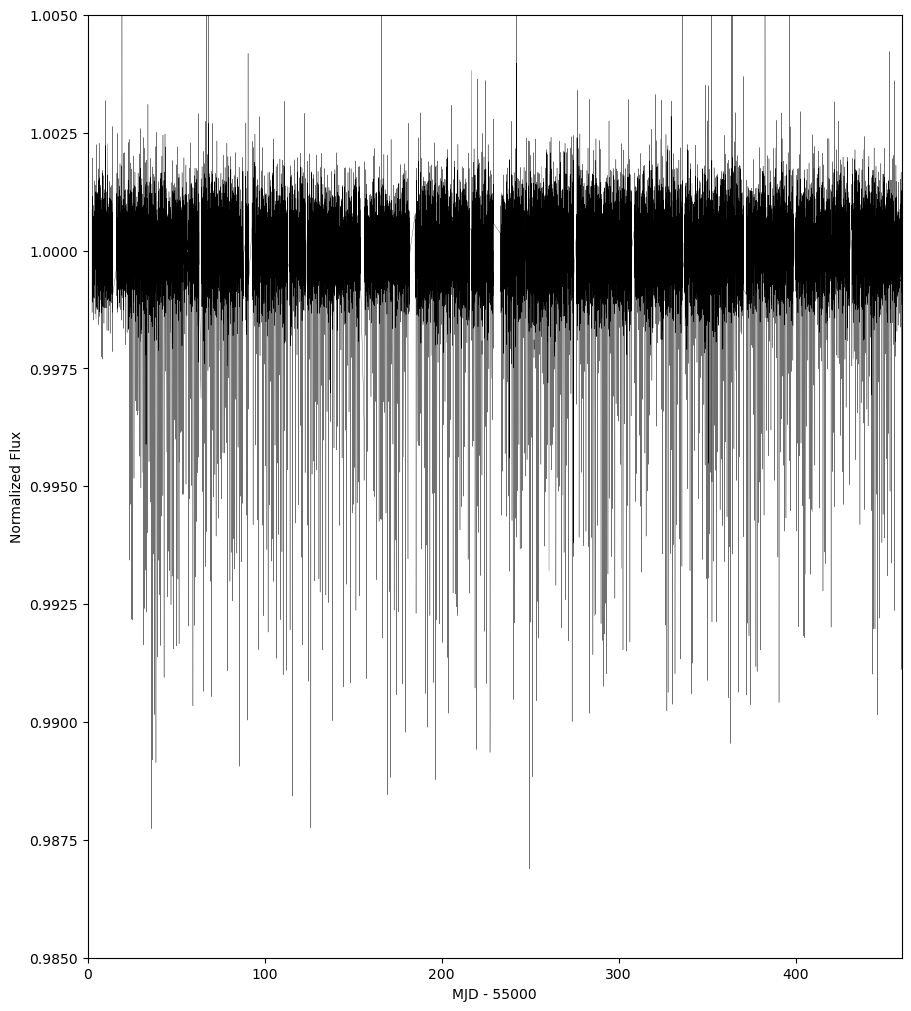

interactive(children=(FloatSlider(value=5.0, description='Sigma clipping value:', max=5.0, min=1.0, readout_fo…

In [15]:
wd.interactive(
    figure_1,
    sigma_value = sigma_slider
)